# 05 · Stage subgroups and interactions

Tests whether the sequencing effect differs by AJCC stage (interaction models), shows stage-specific
IPTW-weighted KM curves (Figure 4), and explores interval × sequencing interactions.
All stages are included here; stage III and IV are the subgroups reported in the paper.

## Load Data

In [1]:
from dataclasses import replace

import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test

from hcc_tace import config
from hcc_tace.cohort import pairwise_cohorts
from hcc_tace.plotting import LARGE
from hcc_tace.survival import (best_logrank_cutpoint, multigroup_logrank_p,
                               stage_sequence_interaction, survival_analysis, survival_analysis_3g)
from hcc_tace.weighting import perform_iptw

config.setup_notebook()
covariates = config.COVARIATES
stage_sub_covariates = [cov for cov in covariates if cov != 'COMBINED_STAGE_GROUP']

df = pd.read_csv(config.ANALYSIS_READY)
df.shape

(1858, 357)

In [2]:
# TACE first vs Systemic first, TACE first vs Same-day, Same-day vs Systemic first
cohorts = pairwise_cohorts(df)
df_tace_sys, df_tace_same, df_same_sys = cohorts['tace_sys'], cohorts['tace_same'], cohorts['same_sys']

In [3]:
df_tace_sys['sequence_group'].value_counts(), df_tace_sys.shape, df_tace_same['sequence_group'].value_counts(), df_tace_same.shape, df_same_sys['sequence_group'].value_counts(), df_same_sys.shape, df['sequence_group'].value_counts(), df.shape

(sequence_group
 0    1212
 1     284
 Name: count, dtype: int64,
 (1496, 357),
 sequence_group
 0    1212
 1     362
 Name: count, dtype: int64,
 (1574, 357),
 sequence_group
 0    362
 1    284
 Name: count, dtype: int64,
 (646, 357),
 sequence_group
 0    1212
 2     362
 1     284
 Name: count, dtype: int64,
 (1858, 357))

## IPTW

In [4]:
df_tace_sys = perform_iptw(df_tace_sys)
df_tace_same = perform_iptw(df_tace_same)
df_same_sys = perform_iptw(df_same_sys)

## Stage * Sequencing

### TACE first vs Systemic first

In [5]:
stage_sequence_interaction(df_tace_sys, categories=[3, 1, 2, 4])

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15015.48
         time fit was run = 2026-11-01 22:29:02 UTC

---
                                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                            
sequence_group                      -0.10      0.90      0.16           -0.41            0.21                0.66                1.23
COMBINED_STAGE_GROUP                 0.26      1.29      0.03            0.19            0.32                1.21                1.38
sequence_group:COMBINED_STAGE_GROUP -0.02      0.98      0.05           -0.11            0.08                0.89                1.08

                                     cmp to     z      p  -log2(p)
covariate                                                         
sequence_group                         0.00 -0.64   0.52      0.93
COMBINED_STAGE_GROUP                   0.00  7.71 <0.005     46.20
sequence_group:COMBINED_STAGE_GROUP    0.00 -0.39   0.70      0.52
---
Concordance = 0.58
Partial AIC = 30036.97
log-likelihood ratio test = 123.70 on 3 df
-log2(p) of ll-ratio test = 86.07

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15009.38
         time fit was run = 2026-11-01 22:29:02 UTC

---
                                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                              
sequence_group                        -0.23      0.79      0.07           -0.37           -0.09                0.69                0.92
COMBINED_STAGE_GROUP_1                -0.49      0.61      0.12           -0.73           -0.25                0.48                0.78
COMBINED_STAGE_GROUP_2                -0.30      0.74      0.09           -0.49           -0.11                0.61                0.89
COMBINED_STAGE_GROUP_4                 0.25      1.28      0.07            0.12            0.38                1.12                1.47
sequence_group:COMBINED_STAGE_GROUP_1 -0.10      0.90      0.18           -0.46            0.25                0.63                1.29
sequence_group:COMBINED_STAGE_GROUP_2  0.38      1.46      0.14            0.11            0.65                1.11                1.91
sequence_group:COMBINED_STAGE_GROUP_4  0.07      1.07      0.10           -0.13            0.26                0.88                1.30

                                       cmp to     z      p  -log2(p)
covariate                                                           
sequence_group                           0.00 -3.17 <0.005      9.38
COMBINED_STAGE_GROUP_1                   0.00 -4.01 <0.005     14.03
COMBINED_STAGE_GROUP_2                   0.00 -3.17 <0.005      9.34
COMBINED_STAGE_GROUP_4                   0.00  3.68 <0.005     12.07
sequence_group:COMBINED_STAGE_GROUP_1    0.00 -0.56   0.58      0.80
sequence_group:COMBINED_STAGE_GROUP_2    0.00  2.73   0.01      7.31
sequence_group:COMBINED_STAGE_GROUP_4    0.00  0.68   0.50      1.01
---
Concordance = 0.58
Partial AIC = 30032.77
log-likelihood ratio test = 135.90 on 7 df
-log2(p) of ll-ratio test = 84.50

### TACE first vs Same day

In [6]:
stage_sequence_interaction(df_tace_same, categories=[3, 1, 2, 4])

<lifelines.CoxPHFitter: fitted with 3141.78 total observations, 863.121 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 3141.78
number of events observed = 2278.66
   partial log-likelihood = -16711.66
         time fit was run = 2026-11-01 22:29:02 UTC

---
                                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                            
sequence_group                      -0.12      0.89      0.15           -0.42            0.18                0.66                1.20
COMBINED_STAGE_GROUP                 0.26      1.29      0.03            0.19            0.32                1.21                1.38
sequence_group:COMBINED_STAGE_GROUP  0.04      1.05      0.05           -0.05            0.13                0.95                1.14

                                     cmp to     z      p  -log2(p)
covariate                                                         
sequence_group                         0.00 -0.79   0.43      1.22
COMBINED_STAGE_GROUP                   0.00  7.81 <0.005     47.34
sequence_group:COMBINED_STAGE_GROUP    0.00  0.95   0.34      1.55
---
Concordance = 0.58
Partial AIC = 33429.33
log-likelihood ratio test = 157.97 on 3 df
-log2(p) of ll-ratio test = 110.62

<lifelines.CoxPHFitter: fitted with 3141.78 total observations, 863.121 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 3141.78
number of events observed = 2278.66
   partial log-likelihood = -16709.56
         time fit was run = 2026-11-01 22:29:03 UTC

---
                                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                              
sequence_group                         0.00      1.00      0.07           -0.13            0.14                0.88                1.15
COMBINED_STAGE_GROUP_1                -0.50      0.61      0.12           -0.74           -0.26                0.48                0.77
COMBINED_STAGE_GROUP_2                -0.31      0.74      0.09           -0.49           -0.12                0.61                0.89
COMBINED_STAGE_GROUP_4                 0.25      1.28      0.07            0.12            0.37                1.12                1.45
sequence_group:COMBINED_STAGE_GROUP_1 -0.23      0.80      0.17           -0.56            0.11                0.57                1.11
sequence_group:COMBINED_STAGE_GROUP_2  0.16      1.17      0.14           -0.12            0.44                0.89                1.55
sequence_group:COMBINED_STAGE_GROUP_4  0.04      1.04      0.09           -0.14            0.22                0.87                1.25

                                       cmp to     z      p  -log2(p)
covariate                                                           
sequence_group                           0.00  0.06   0.95      0.07
COMBINED_STAGE_GROUP_1                   0.00 -4.04 <0.005     14.19
COMBINED_STAGE_GROUP_2                   0.00 -3.24 <0.005      9.68
COMBINED_STAGE_GROUP_4                   0.00  3.74 <0.005     12.40
sequence_group:COMBINED_STAGE_GROUP_1    0.00 -1.34   0.18      2.46
sequence_group:COMBINED_STAGE_GROUP_2    0.00  1.11   0.27      1.90
sequence_group:COMBINED_STAGE_GROUP_4    0.00  0.45   0.65      0.62
---
Concordance = 0.58
Partial AIC = 33433.12
log-likelihood ratio test = 162.18 on 7 df
-log2(p) of ll-ratio test = 102.82

### Same day vs Systemic first

In [7]:
stage_sequence_interaction(df_same_sys, categories=[3, 1, 2, 4])

<lifelines.CoxPHFitter: fitted with 1284.81 total observations, 429.589 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 1284.81
number of events observed = 855.221
   partial log-likelihood = -5477.10
         time fit was run = 2026-11-01 22:29:03 UTC

---
                                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                            
sequence_group                       0.32      1.37      0.24           -0.16            0.79                0.85                2.21
COMBINED_STAGE_GROUP                 0.38      1.47      0.05            0.28            0.48                1.32                1.62
sequence_group:COMBINED_STAGE_GROUP -0.16      0.85      0.07           -0.30           -0.01                0.74                0.99

                                     cmp to     z      p  -log2(p)
covariate                                                         
sequence_group                         0.00  1.31   0.19      2.38
COMBINED_STAGE_GROUP                   0.00  7.36 <0.005     42.29
sequence_group:COMBINED_STAGE_GROUP    0.00 -2.16   0.03      5.02
---
Concordance = 0.60
Partial AIC = 10960.20
log-likelihood ratio test = 85.31 on 3 df
-log2(p) of ll-ratio test = 58.64

<lifelines.CoxPHFitter: fitted with 1284.81 total observations, 429.589 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 1284.81
number of events observed = 855.221
   partial log-likelihood = -5475.39
         time fit was run = 2026-11-01 22:29:03 UTC

---
                                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                              
sequence_group                        -0.10      0.91      0.11           -0.32            0.12                0.73                1.13
COMBINED_STAGE_GROUP_1                -0.92      0.40      0.19           -1.30           -0.54                0.27                0.59
COMBINED_STAGE_GROUP_2                -0.23      0.79      0.17           -0.56            0.10                0.57                1.10
COMBINED_STAGE_GROUP_4                 0.36      1.43      0.11            0.15            0.57                1.16                1.77
sequence_group:COMBINED_STAGE_GROUP_1  0.28      1.32      0.28           -0.27            0.82                0.77                2.26
sequence_group:COMBINED_STAGE_GROUP_2 -0.05      0.95      0.23           -0.50            0.41                0.61                1.50
sequence_group:COMBINED_STAGE_GROUP_4 -0.25      0.78      0.15           -0.55            0.05                0.58                1.06

                                       cmp to     z      p  -log2(p)
covariate                                                           
sequence_group                           0.00 -0.86   0.39      1.36
COMBINED_STAGE_GROUP_1                   0.00 -4.72 <0.005     18.72
COMBINED_STAGE_GROUP_2                   0.00 -1.39   0.17      2.59
COMBINED_STAGE_GROUP_4                   0.00  3.35 <0.005     10.27
sequence_group:COMBINED_STAGE_GROUP_1    0.00  1.00   0.32      1.65
sequence_group:COMBINED_STAGE_GROUP_2    0.00 -0.20   0.84      0.25
sequence_group:COMBINED_STAGE_GROUP_4    0.00 -1.61   0.11      3.21
---
Concordance = 0.60
Partial AIC = 10964.77
log-likelihood ratio test = 88.74 on 7 df
-log2(p) of ll-ratio test = 51.98

## Spacing * Sequence group

### Setup

In [8]:
df = df_tace_sys.copy()

In [9]:
df['treatment_spacing'] =  abs(df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS'])

In [10]:
best_cut_all, best_stat_all = best_logrank_cutpoint(df)
print("Optimal cutpoint (days):", best_cut_all, "– log‐rank stat:", best_stat_all)

Optimal cutpoint (days): 103 – log‐rank stat: 29.594547721278285


In [11]:
spacings = ['spacing_binary', 'spacing_quartile', 'spacing_3090', 'spacing_week']

df['spacing_quartile'] = pd.qcut(df['treatment_spacing'], q=4, labels=['<29 days', '30-64 days', '65-125 days', '>125 days'])
quartile_cutoffs = df['treatment_spacing'].quantile([0.25, 0.5, 0.75]).values
print("Quartile cutoffs:", quartile_cutoffs)

df['spacing_3090'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)
df['spacing_week'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)
df['spacing_binary'] = (df['treatment_spacing'] > best_cut_all).astype(int).map({0: '≤' + str(best_cut_all) + ' days', 1: '>' + str(best_cut_all) + ' days'})

Quartile cutoffs: [ 31.  65. 125.]


### Quartile

In [12]:
df['spacing_quartile'] = pd.Categorical(
    df['spacing_quartile'],
    categories=['30-64 days', '65-125 days', '<29 days', '>125 days'],
    ordered=True
)

cph_q = CoxPHFitter()
cph_q.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_quartile'
)
cph_q.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15029.86
         time fit was run = 2026-11-01 22:29:04 UTC

---
                                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                       
sequence_group                                 -0.49      0.62      0.09           -0.66           -0.31                0.52                0.73
spacing_quartile[T.65-125 days]                -0.18      0.83      0.08           -0.35           -0.01                0.71                0.99
spacing_quartile[T.<29 days]                   -0.09      0.92      0.09           -0.26            0.08                0.77                1.08
spacing_quartile[T.>125 days]                  -0.44      0.64      0.09           -0.61           -0.28                0.54                0.76
sequence_group:spacing_quartile[T.65-125 days]  0.68      1.98      0.13            0.44            0.93                1.55                2.53
sequence_group:spacing_quartile[T.<29 days]     0.33      1.39      0.12            0.09            0.56                1.09                1.75
sequence_group:spacing_quartile[T.>125 days]    0.27      1.31      0.13            0.01            0.53                1.01                1.70

                                                cmp to     z      p  -log2(p)
covariate                                                                    
sequence_group                                    0.00 -5.55 <0.005     25.03
spacing_quartile[T.65-125 days]                   0.00 -2.14   0.03      4.93
spacing_quartile[T.<29 days]                      0.00 -1.02   0.31      1.70
spacing_quartile[T.>125 days]                     0.00 -5.20 <0.005     22.26
sequence_group:spacing_quartile[T.65-125 days]    0.00  5.45 <0.005     24.21
sequence_group:spacing_quartile[T.<29 days]       0.00  2.71   0.01      7.20
sequence_group:spacing_quartile[T.>125 days]      0.00  2.03   0.04      4.57
---
Concordance = 0.58
Partial AIC = 30073.73
log-likelihood ratio test = 94.94 on 7 df
-log2(p) of ll-ratio test = 56.22

In [13]:
df['spacing_quartile'] = df['spacing_quartile'].cat.codes
cph_q = CoxPHFitter()
cph_q.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_quartile'
)
cph_q.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15059.18
         time fit was run = 2026-11-01 22:29:04 UTC

---
                                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                        
sequence_group                  -0.29      0.75      0.07           -0.43           -0.15                0.65                0.87
spacing_quartile                -0.13      0.88      0.03           -0.18           -0.07                0.84                0.93
sequence_group:spacing_quartile  0.08      1.09      0.04            0.01            0.16                1.01                1.17

                                 cmp to     z      p  -log2(p)
covariate                                                     
sequence_group                     0.00 -3.99 <0.005     13.86
spacing_quartile                   0.00 -4.72 <0.005     18.68
sequence_group:spacing_quartile    0.00  2.13   0.03      4.90
---
Concordance = 0.58
Partial AIC = 30124.37
log-likelihood ratio test = 36.30 on 3 df
-log2(p) of ll-ratio test = 23.88

### 30,90

In [14]:
# df['spacing_3090'] = pd.Categorical(
#     df['spacing_3090'],
#     categories=['>90 days', '≤30 days', '31–90 days'],
#     ordered=True
# )

cph_3090 = CoxPHFitter()
cph_3090.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_3090'
)
cph_3090.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15052.79
         time fit was run = 2026-11-01 22:29:05 UTC

---
                                           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                  
sequence_group                            -0.13      0.88      0.08           -0.30            0.03                0.74                1.03
spacing_3090[T.31–90 days]                 0.05      1.05      0.08           -0.11            0.20                0.90                1.22
spacing_3090[T.>90 days]                  -0.30      0.74      0.08           -0.46           -0.14                0.63                0.87
sequence_group:spacing_3090[T.31–90 days] -0.18      0.83      0.11           -0.40            0.03                0.67                1.03
sequence_group:spacing_3090[T.>90 days]    0.06      1.06      0.12           -0.17            0.28                0.84                1.33

                                           cmp to     z      p  -log2(p)
covariate                                                               
sequence_group                               0.00 -1.60   0.11      3.19
spacing_3090[T.31–90 days]                   0.00  0.60   0.55      0.86
spacing_3090[T.>90 days]                     0.00 -3.78 <0.005     12.61
sequence_group:spacing_3090[T.31–90 days]    0.00 -1.70   0.09      3.48
sequence_group:spacing_3090[T.>90 days]      0.00  0.48   0.63      0.67
---
Concordance = 0.58
Partial AIC = 30115.58
log-likelihood ratio test = 49.09 on 5 df
-log2(p) of ll-ratio test = 28.81

In [15]:
df['spacing_3090'] = df['spacing_3090'].cat.codes
cph_3090 = CoxPHFitter()
cph_3090.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_3090'
)
cph_3090.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15057.72
         time fit was run = 2026-11-01 22:29:05 UTC

---
                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                    
sequence_group              -0.23      0.80      0.07           -0.37           -0.09                0.69                0.92
spacing_3090                -0.17      0.85      0.04           -0.24           -0.09                0.79                0.91
sequence_group:spacing_3090  0.04      1.04      0.06           -0.07            0.15                0.93                1.17

                             cmp to     z      p  -log2(p)
covariate                                                 
sequence_group                 0.00 -3.15 <0.005      9.24
spacing_3090                   0.00 -4.37 <0.005     16.32
sequence_group:spacing_3090    0.00  0.76   0.45      1.16
---
Concordance = 0.57
Partial AIC = 30121.44
log-likelihood ratio test = 39.23 on 3 df
-log2(p) of ll-ratio test = 25.94

### Week

In [16]:
df['spacing_week'] = pd.Categorical(
    df['spacing_week'],
    categories=['15–28 days', '8–14 days', '≤7 days', '>28 days'],
    ordered=True
)

cph_week = CoxPHFitter()
# cph_week.fit(
#     df,
#     duration_col='time',
#     event_col='event',
#     weights_col='iptw_weight',
#     formula='sequence_group * spacing_week'
# )
# cph_week.print_summary()

In [17]:
df['spacing_week'] = df['spacing_week'].cat.codes
cph_week = CoxPHFitter()
cph_week.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_week'
)
cph_week.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15055.36
         time fit was run = 2026-11-01 22:29:05 UTC

---
                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                    
sequence_group               0.18      1.20      0.10           -0.02            0.38                0.98                1.47
spacing_week                -0.02      0.98      0.03           -0.07            0.03                0.93                1.03
sequence_group:spacing_week -0.14      0.87      0.04           -0.22           -0.07                0.80                0.94

                             cmp to     z      p  -log2(p)
covariate                                                 
sequence_group                 0.00  1.76   0.08      3.68
spacing_week                   0.00 -0.74   0.46      1.12
sequence_group:spacing_week    0.00 -3.64 <0.005     11.82
---
Concordance = 0.53
Partial AIC = 30116.71
log-likelihood ratio test = 43.96 on 3 df
-log2(p) of ll-ratio test = 29.27

### Binary

In [18]:
cph_binary = CoxPHFitter()

df['spacing_binary'] = pd.Categorical(
    df['spacing_binary'],
    categories=['≤119 days', '>119 days'],
    ordered=True
)

cph_binary.fit(
    df,
    duration_col='time',
    event_col='event',
    weights_col='iptw_weight',
    formula='sequence_group * spacing_binary'
)
cph_binary.print_summary()

<lifelines.CoxPHFitter: fitted with 2958.25 total observations, 899.201 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2958.25
number of events observed = 2059.05
   partial log-likelihood = -15077.33
         time fit was run = 2026-11-01 22:29:05 UTC

---
Empty DataFrame
Columns: [ coef,  exp(coef),  se(coef),  coef lower 95%,  coef upper 95%,  exp(coef) lower 95%,  exp(coef) upper 95%]
Index: []

Empty DataFrame
Columns: [ cmp to,  z,  p,  -log2(p)]
Index: []
---
Concordance = 0.50
Partial AIC = 30154.67
log-likelihood ratio test = 0.00 on 0 df
-log2(p) of ll-ratio test = nan

## Stage subgroup KM plots

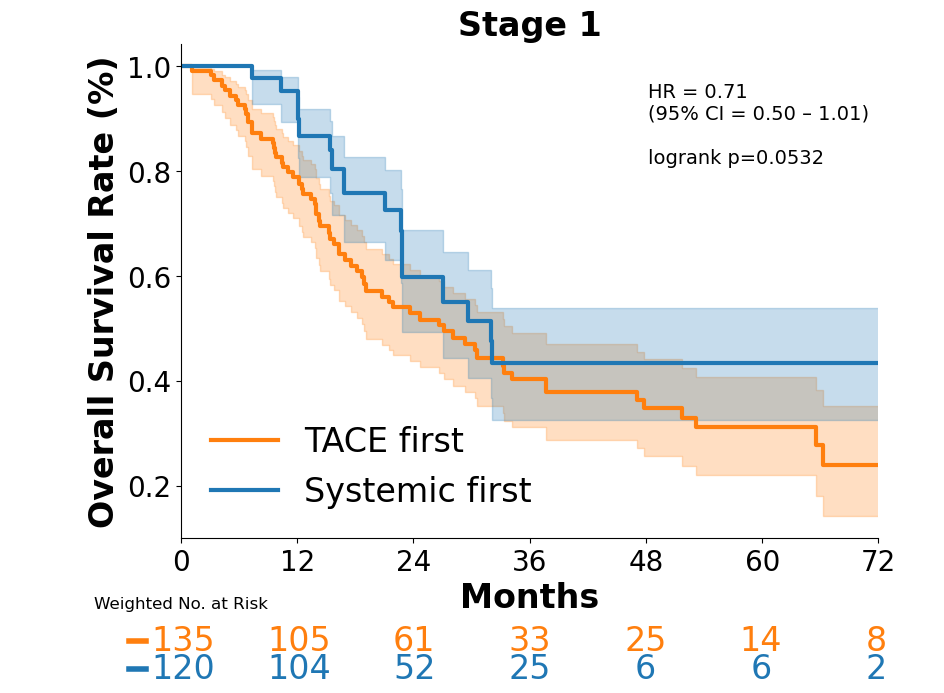

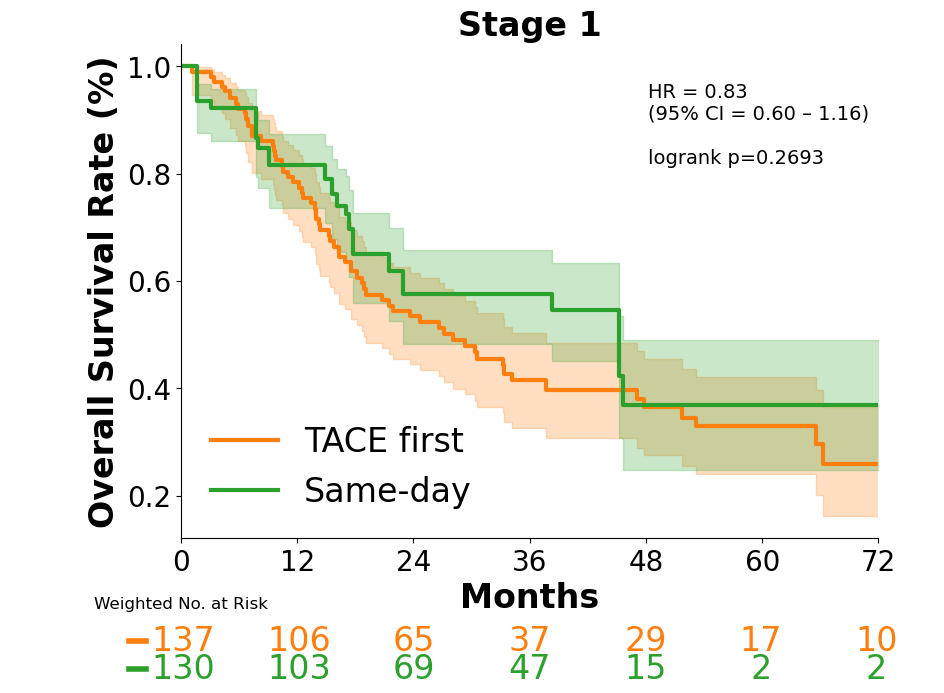

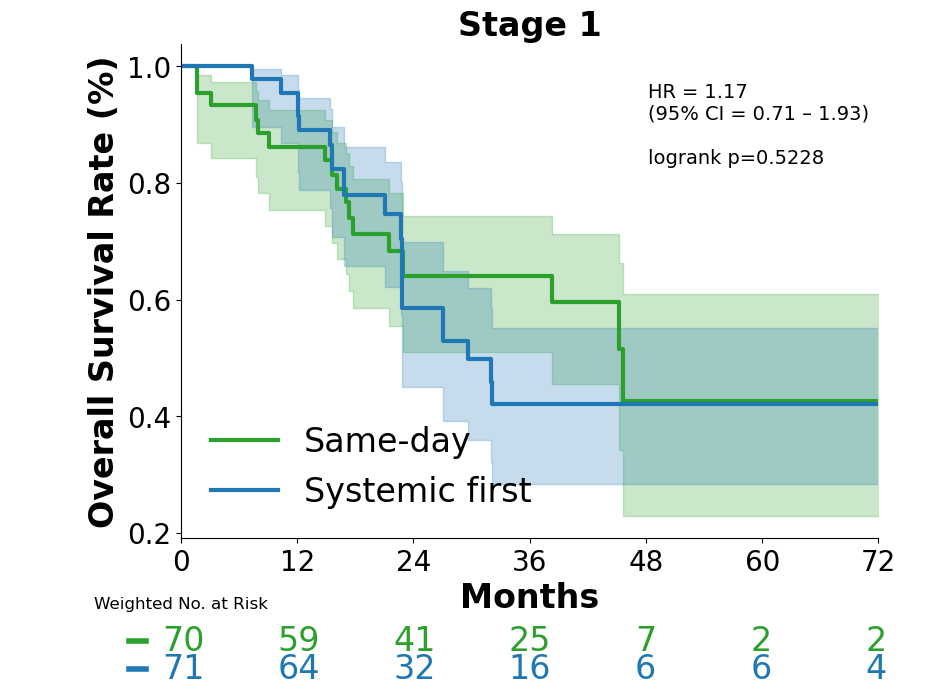

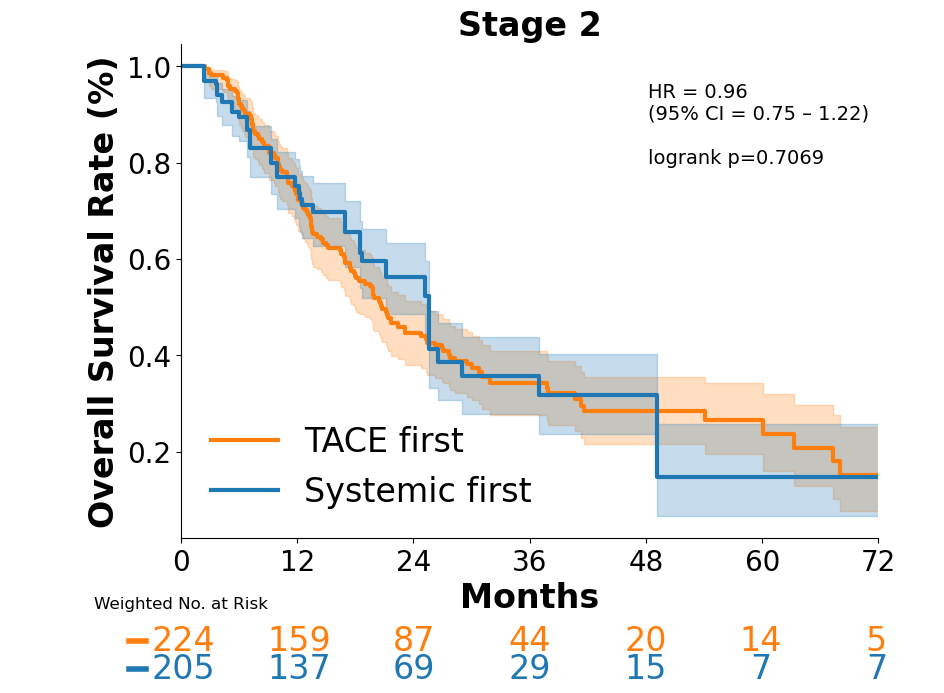

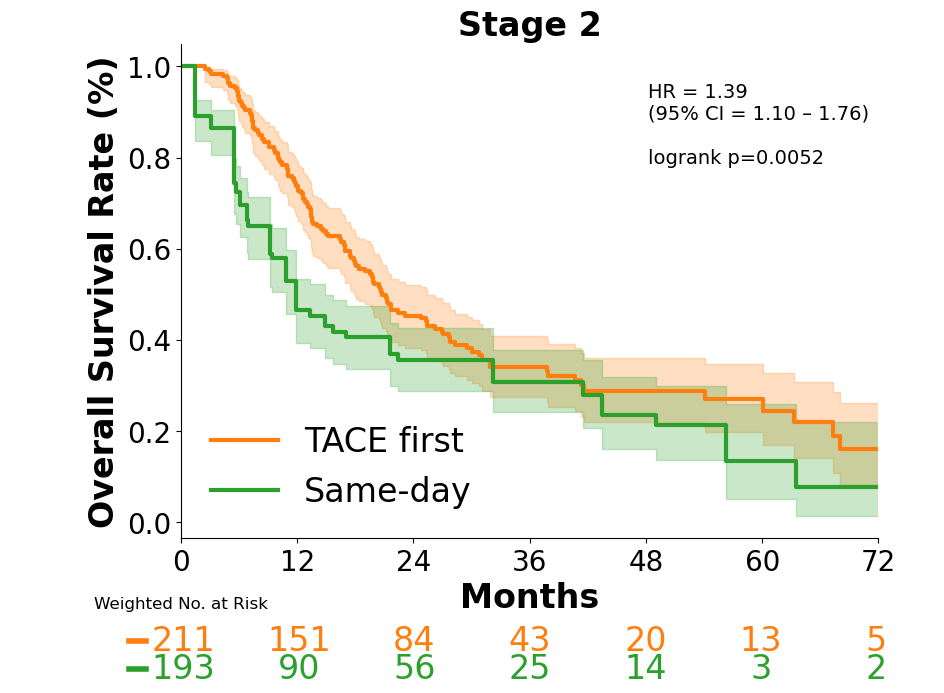

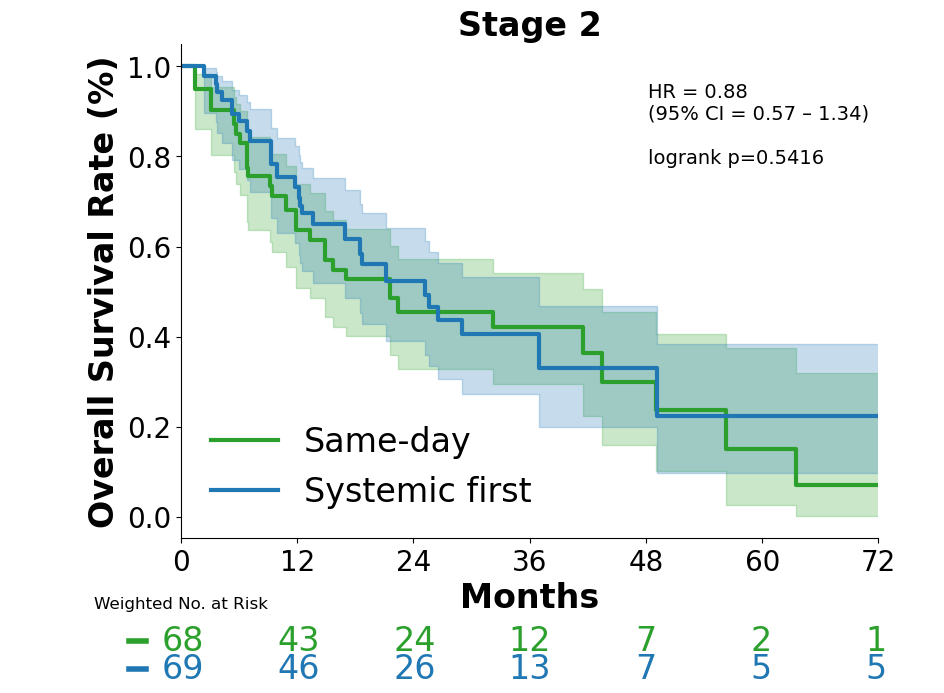

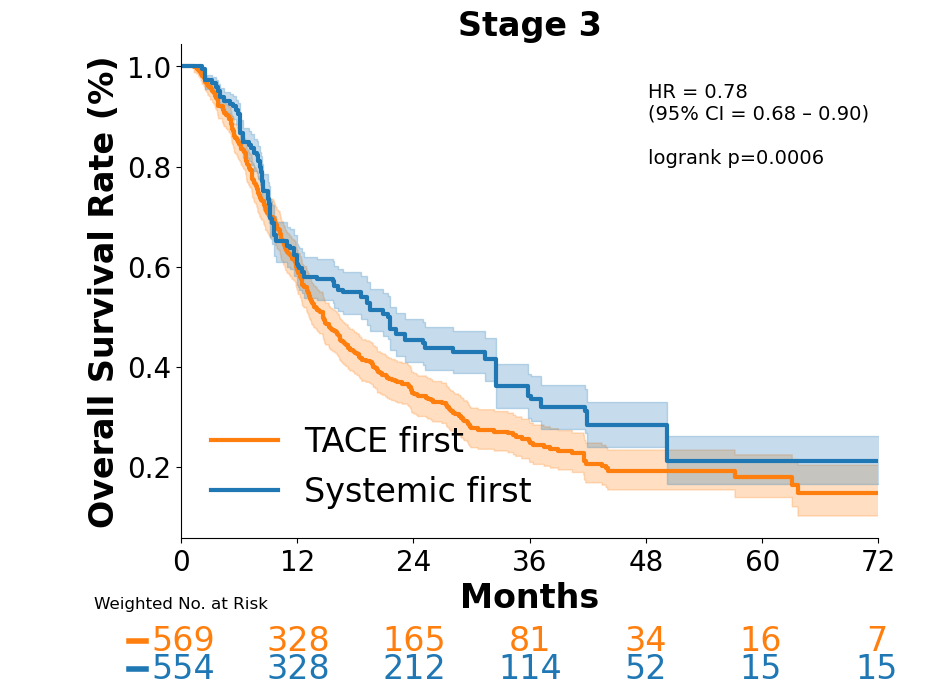

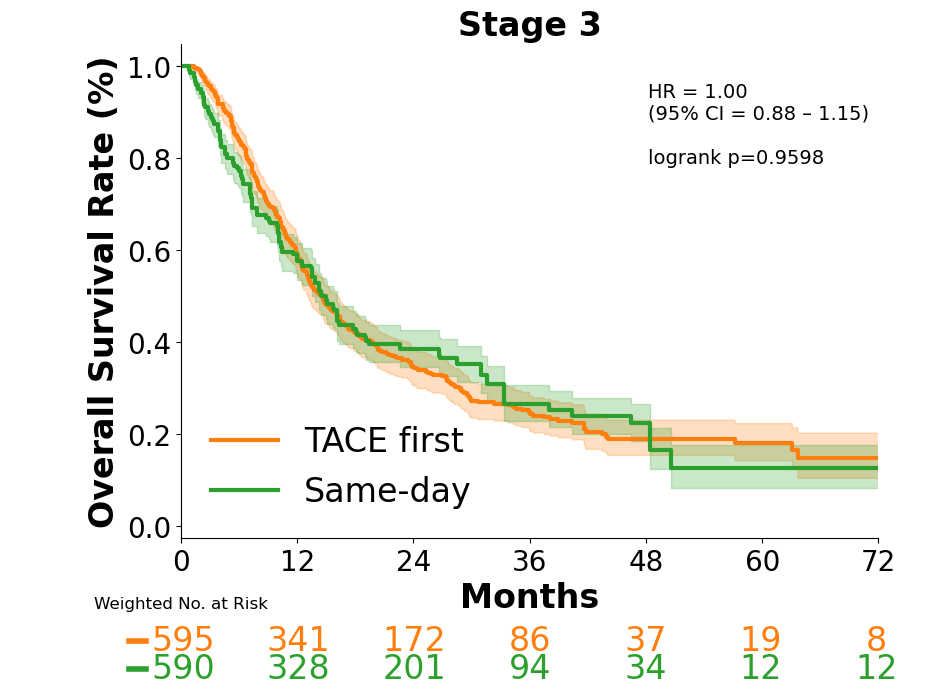

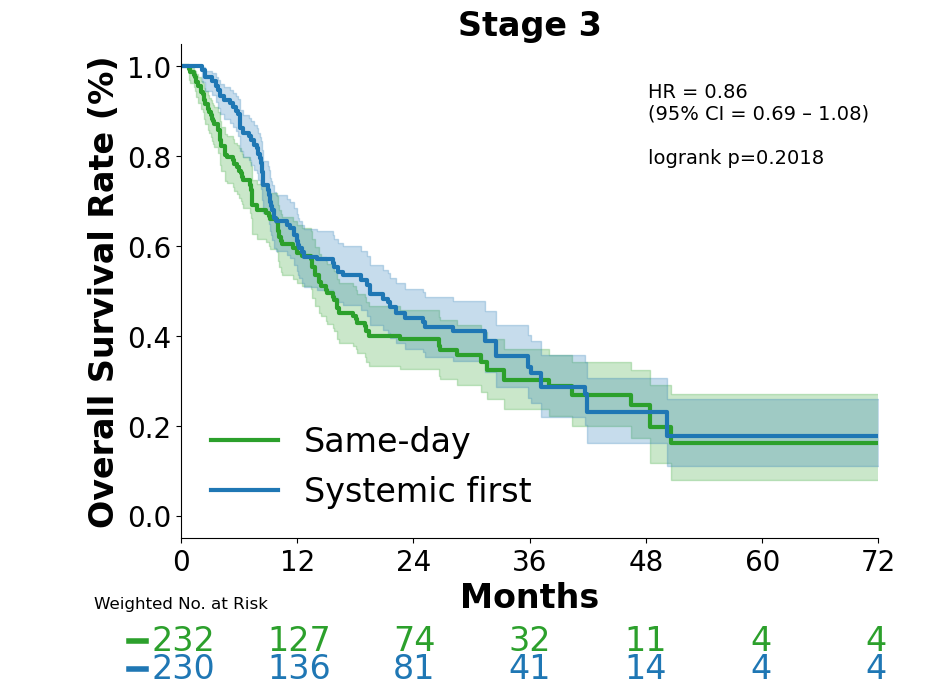

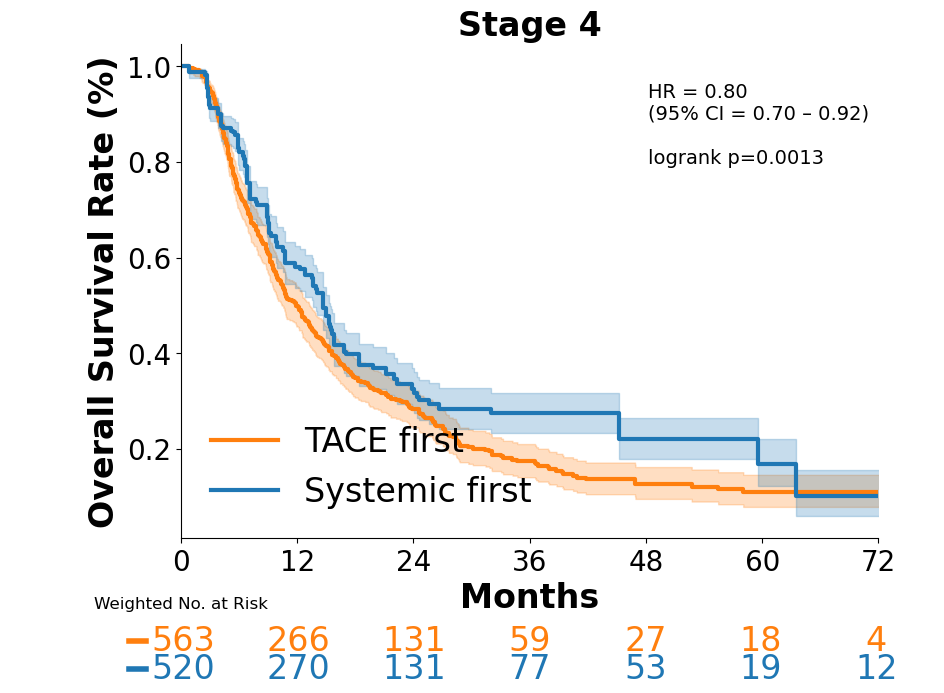

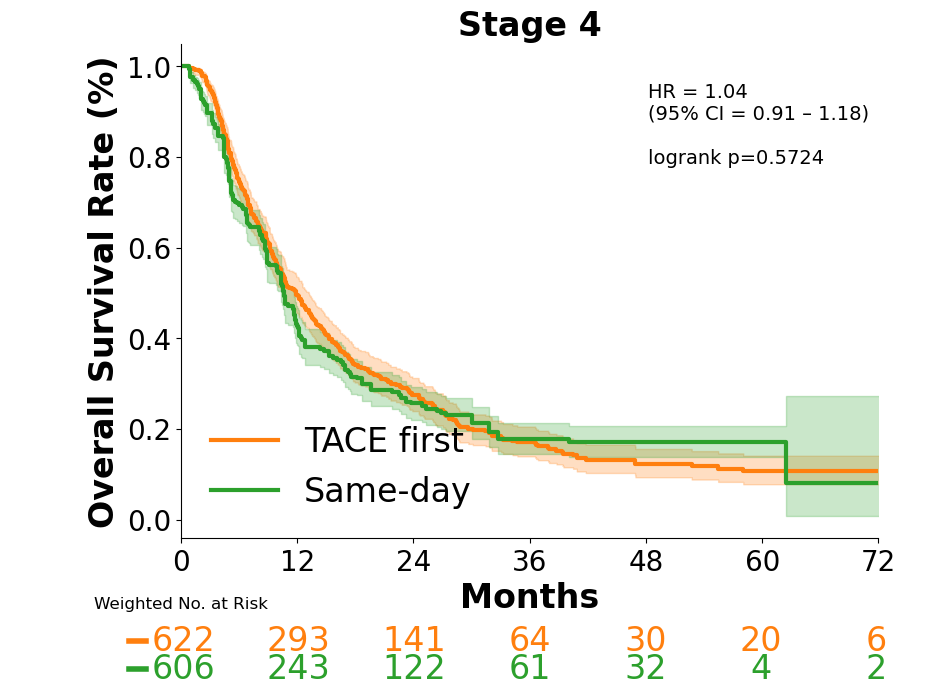

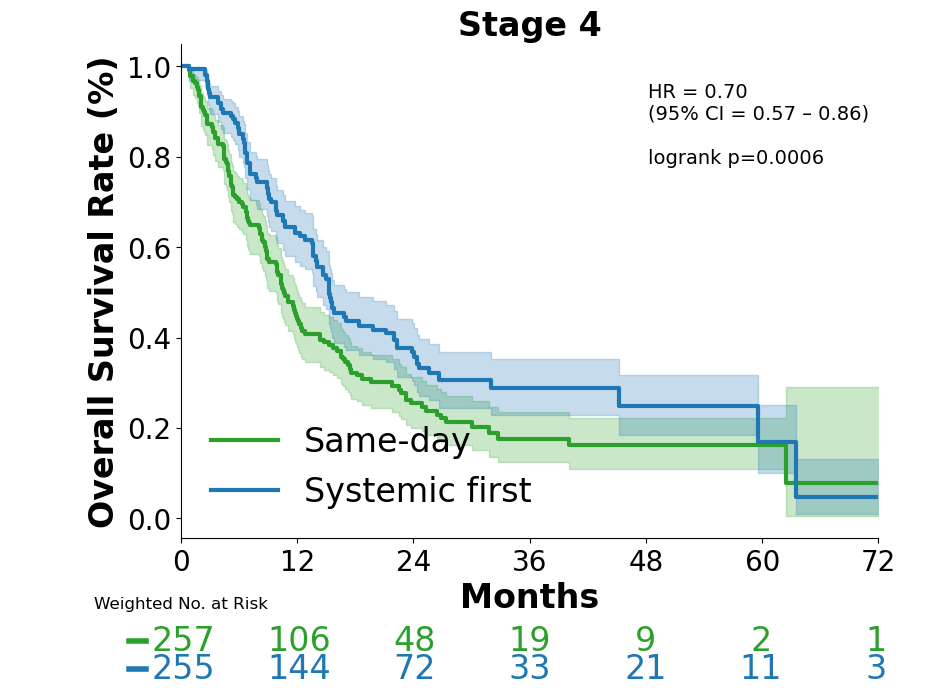

In [19]:
comparisons = [
    ['TACE first', 'Systemic first', ['#ff7f0e', '#1f77b4'], df_tace_sys],
    ['TACE first', 'Same-day', ['#ff7f0e', '#2ca02c'], df_tace_same],
    ['Same-day', 'Systemic first', ['#2ca02c', '#1f77b4'], df_same_sys]
]


p_value_df = pd.DataFrame()

for stage in [1, 2, 3, 4]:
    row = {'Stage': stage}
    for comparison in comparisons:
        combo_name = f"{comparison[0]} vs {comparison[1]} Stage {stage}"

        groups = comparison[:2]
        df_comparison = comparison[3]
        df_stage = df_comparison[df_comparison['COMBINED_STAGE_GROUP'] == stage].copy()
        df_stage = perform_iptw(df_stage, covariates=stage_sub_covariates)

        survival_analysis(
            df_stage,
            time_grid=config.TIME_GRID,
            groups=groups,
            title=f"Stage {stage}",
            weight_col='iptw_weight',
            colors=comparison[2],
            style=LARGE, print_summary=False, print_landmarks=False,
            #file_name=f"{combo_name.replace(' ', '_').lower()}"
        )

        results = logrank_test(
            df_stage[df_stage['sequence_group'] == 0]['time'],
            df_stage[df_stage['sequence_group'] == 1]['time'],
            event_observed_A=df_stage[df_stage['sequence_group'] == 0]['event'],
            event_observed_B=df_stage[df_stage['sequence_group'] == 1]['event'],
            weights_A=df_stage[df_stage['sequence_group'] == 0]['iptw_weight'],
            weights_B=df_stage[df_stage['sequence_group'] == 1]['iptw_weight']
        )
        row[f"{groups[0]} vs {groups[1]}"] = results.p_value
    p_value_df = pd.concat([p_value_df, pd.DataFrame([row])], ignore_index=True)

In [20]:
p_value_df

,Stage,TACE first vs Systemic first,TACE first vs Same-day,Same-day vs Systemic first
0,1,0.053165,0.269349,0.522788
1,2,0.706864,0.005182,0.541569
2,3,0.000620,0.959825,0.201848
3,4,0.001257,0.572354,0.000559


## 3 group stage subgroup KM plots


Stage 1


<lifelines.CoxPHFitter: fitted with 173 total observations, 77 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 173
number of events observed = 96
   partial log-likelihood = -435.48
         time fit was run = 2026-11-01 22:29:09 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1      0.38      1.46      0.29           -0.19            0.94                0.83                2.57
seq_2      0.10      1.10      0.35           -0.59            0.79                0.56                2.20

           cmp to    z    p  -log2(p)
covariate                            
seq_1        0.00 1.30 0.19      2.37
seq_2        0.00 0.28 0.78      0.36
---
Concordance = 0.55
Partial AIC = 874.97
log-likelihood ratio test = 2.37 on 2 df
-log2(p) of ll-ratio test = 1.71

Systemic First at 36 mo: 43.8% (23.5%-62.5%)
Systemic First at 60 mo: 43.8% (23.5%-62.5%)
TACE First at 36 mo: 40.0% (29.7%-50.0%)
TACE First at 60 mo: 31.2% (21.1%-41.8%)
Same-Day at 36 mo: 59.8% (41.7%-74.0%)
Same-Day at 60 mo: 37.6% (15.8%-59.6%)


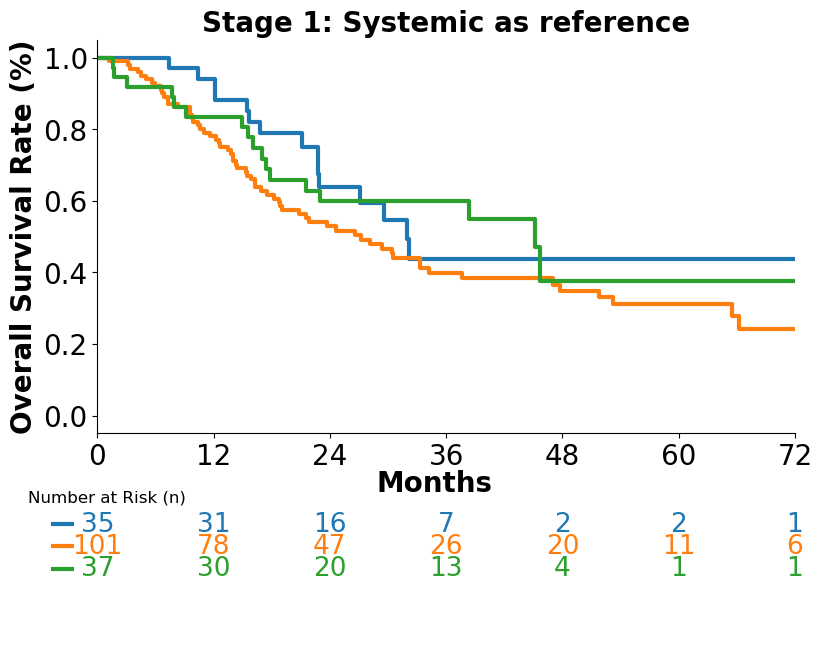

Stage 1 log-rank p-value: 0.3158

Stage 2


<lifelines.CoxPHFitter: fitted with 259 total observations, 88 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 259
number of events observed = 171
   partial log-likelihood = -835.59
         time fit was run = 2026-11-01 22:29:09 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1     -0.02      0.98      0.22           -0.44            0.41                0.64                1.50
seq_2      0.02      1.02      0.28           -0.53            0.58                0.59                1.78

           cmp to     z    p  -log2(p)
covariate                             
seq_1        0.00 -0.07 0.94      0.08
seq_2        0.00  0.08 0.94      0.10
---
Concordance = 0.51
Partial AIC = 1675.19
log-likelihood ratio test = 0.03 on 2 df
-log2(p) of ll-ratio test = 0.02

Systemic First at 36 mo: 36.4% (14.5%-47.9%)
Systemic First at 60 mo: 20.2% (5.2%-42.2%)
TACE First at 36 mo: 34.3% (27.0%-41.6%)
TACE First at 60 mo: 26.6% (16.1%-33.2%)
Same-Day at 36 mo: 42.2% (25.1%-58.5%)
Same-Day at 60 mo: 16.1% (0.6%-28.7%)


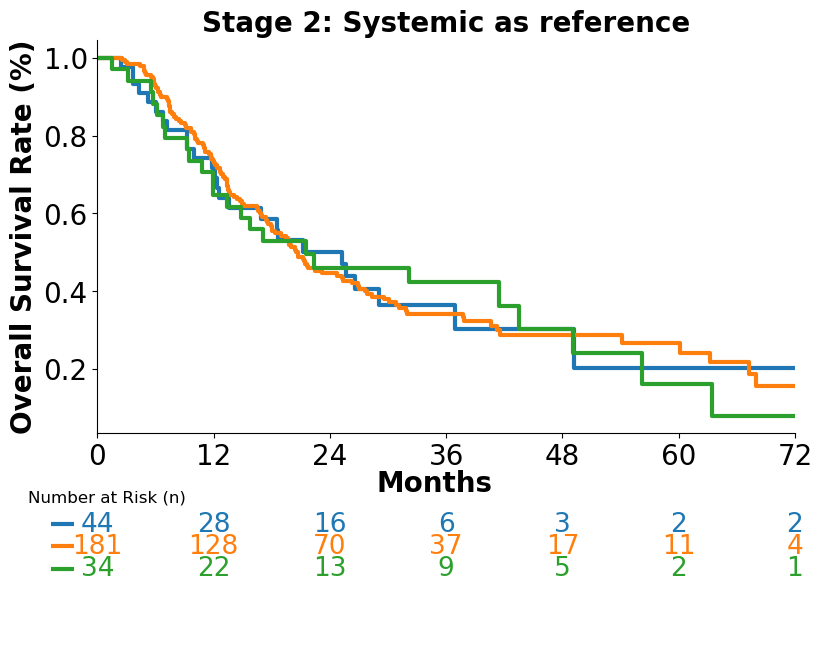

Stage 2 log-rank p-value: 0.9845

Stage 3


<lifelines.CoxPHFitter: fitted with 701 total observations, 199 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 701
number of events observed = 502
   partial log-likelihood = -2949.02
         time fit was run = 2026-11-01 22:29:09 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1      0.14      1.15      0.13           -0.12            0.40                0.89                1.49
seq_2      0.13      1.14      0.16           -0.18            0.45                0.84                1.57

           cmp to    z    p  -log2(p)
covariate                            
seq_1        0.00 1.07 0.28      1.82
seq_2        0.00 0.84 0.40      1.31
---
Concordance = 0.51
Partial AIC = 5902.04
log-likelihood ratio test = 1.21 on 2 df
-log2(p) of ll-ratio test = 0.87

Systemic First at 36 mo: 31.2% (18.9%-39.9%)
Systemic First at 60 mo: 15.3% (5.7%-29.1%)
TACE First at 36 mo: 24.8% (20.3%-28.8%)
TACE First at 60 mo: 18.0% (13.7%-22.8%)
Same-Day at 36 mo: 30.1% (21.8%-38.8%)
Same-Day at 60 mo: 16.4% (7.4%-28.6%)


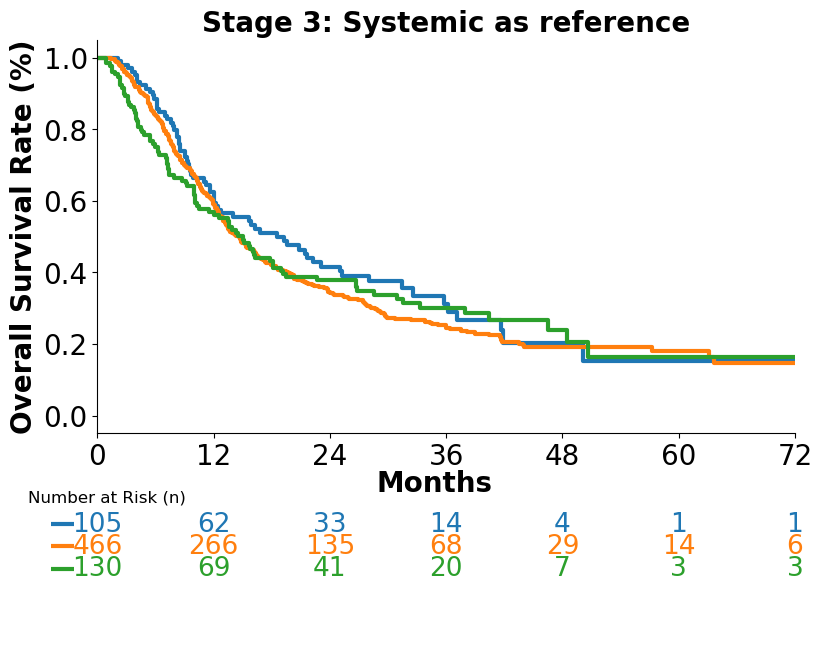

Stage 3 log-rank p-value: 0.5577

Stage 4


<lifelines.CoxPHFitter: fitted with 725 total observations, 162 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 725
number of events observed = 563
   partial log-likelihood = -3287.43
         time fit was run = 2026-11-01 22:29:09 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
seq_1      0.24      1.27      0.13           -0.02            0.50                0.98                1.64
seq_2      0.33      1.39      0.15            0.03            0.62                1.03                1.87

           cmp to    z    p  -log2(p)
covariate                            
seq_1        0.00 1.78 0.08      3.73
seq_2        0.00 2.16 0.03      5.01
---
Concordance = 0.53
Partial AIC = 6578.87
log-likelihood ratio test = 4.95 on 2 df
-log2(p) of ll-ratio test = 3.57

Systemic First at 36 mo: 26.3% (17.1%-36.4%)
Systemic First at 60 mo: 14.6% (4.3%-30.9%)


TACE First at 36 mo: 17.8% (14.2%-21.8%)
TACE First at 60 mo: 11.1% (7.8%-15.1%)
Same-Day at 36 mo: 16.7% (10.5%-24.0%)
Same-Day at 60 mo: 15.0% (8.9%-22.5%)


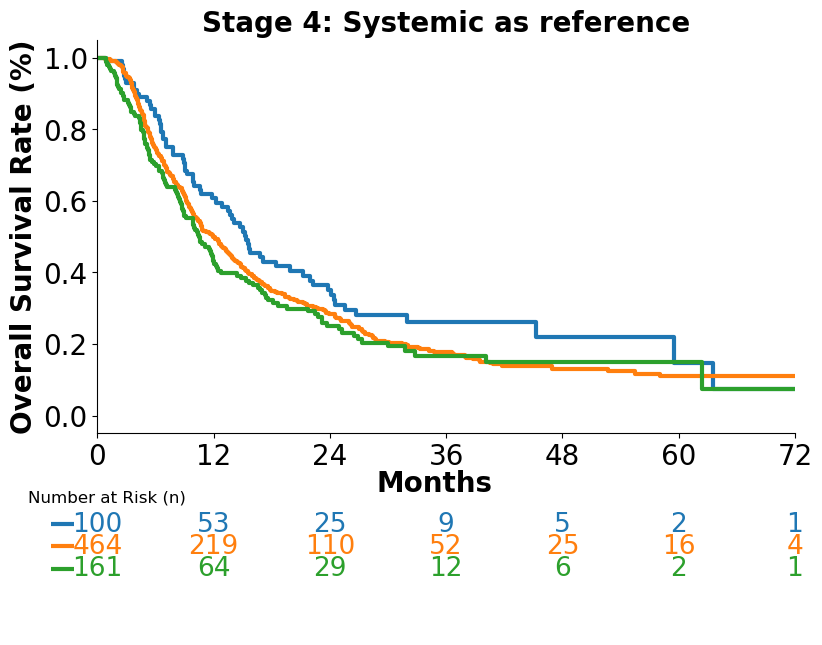

Stage 4 log-rank p-value: 0.0932


In [21]:
df = pd.read_csv(config.ANALYSIS_READY)

df['sequence_group_sys'] = df['sequence_group'].map({
    1: 0,   # systemic → reference level
    0: 1,   # TACE    → new level 1
    2: 2    # same-day→ level 2
})

for stage in [1, 2, 3, 4]:
    df_stage = df[df['COMBINED_STAGE_GROUP'] == stage].copy()
    print(f"\nStage {stage}")
    survival_analysis_3g(
        df_stage,
        time_grid=config.TIME_GRID,
        group_col='sequence_group_sys',
        ref_group='Systemic',
        simultaneous_label='Same-Day',
        title=f"Stage {stage}",
        style=replace(LARGE, legend_3g=False),
        # file_name=f"stage_{stage}_3group"
    )
    print(f"Stage {stage} log-rank p-value: {multigroup_logrank_p(df_stage, 'sequence_group_sys'):.4f}")